# CreditParity – Step 5
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 5:** Threshold optimization and the three-zone decision policy

## Step 5 · Threshold Optimization and Decision Policy

**Goal.** Step 4 settled the model (logistic regression). Now we decide *what to do* with its default probability:
- **a)** Find the cost-optimal threshold based on the 5:1 cost matrix and compare it with the default threshold of 0.5.
- **b)** Organize the decisions in a three-zone human-in-the-loop policy: 🟢 auto-approve, 🟡 manual review, 🔴 decline recommended.
- **c)** Choose the thresholds with **cross-validation on the training set** and use the test set **only once**, for the final evaluation.

**How we avoid overfitting the thresholds.** We create *out-of-fold* predictions for the 4,000 training applications: each application is scored by a model trained on the other four folds (5-fold stratified CV, the same folds as in Step 4). These predictions behave like predictions on new data, so we can tune thresholds on them without touching the test set.

**Cost assumption.** A missed default (FN) costs 5, a rejected good customer (FP) costs 1. This is the classic assumption for this dataset, not an estimate from real loss data.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, confusion_matrix

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}

COST_FN = 5   # missed default
COST_FP = 1   # rejected good customer

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 and 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Final model from Step 4: logistic regression with default settings
def make_model():
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("num", StandardScaler(), numeric)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

# Out-of-fold default probabilities for the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_oof = cross_val_predict(make_model(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
y_oof = y_train.to_numpy()
fold_id = np.empty(len(y_oof), dtype=int)
for k, (_, val_idx) in enumerate(cv.split(X_train, y_train)):
    fold_id[val_idx] = k
print("Out-of-fold predictions:", len(p_oof), "| mean predicted PD:", round(p_oof.mean(), 3),
      "| observed default rate:", round(y_oof.mean(), 3))

Out-of-fold predictions: 4000 | mean predicted PD: 0.335 | observed default rate: 0.334


### a) The cost-optimal threshold

With a threshold *t*, every application with a default probability ≥ *t* is declined. The total cost is

$$\text{Cost}(t) = 5 \cdot \text{FN}(t) + 1 \cdot \text{FP}(t).$$

If the probabilities were perfectly calibrated, theory says the optimum is $t^* = \frac{1}{1+5} \approx 0.17$: decline as soon as the expected loss of approving (5 · PD) exceeds the expected loss of declining (1 · (1 − PD)). We search the actual optimum on a grid of thresholds.

In [3]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def single_threshold_metrics(p, y_true, t):
    """Decline if p >= t. Returns cost and standard metrics."""
    decline = p >= t
    fn = int(((~decline) & (y_true == 1)).sum())
    fp = int((decline & (y_true == 0)).sum())
    return {"Threshold": t,
            "Cost": COST_FN * fn + COST_FP * fp,
            "Cost per 100 applications": 100 * (COST_FN * fn + COST_FP * fp) / len(y_true),
            "Recall": recall_score(y_true, decline),
            "Precision": precision_score(y_true, decline, zero_division=0),
            "Approval rate": 1 - decline.mean(),
            "FN": fn, "FP": fp}

cost_curve = pd.DataFrame([single_threshold_metrics(p_oof, y_oof, t) for t in THRESHOLDS])
T_OPT = float(cost_curve.loc[cost_curve["Cost"].idxmin(), "Threshold"])
near_opt = cost_curve.loc[cost_curve["Cost"] <= 1.02 * cost_curve["Cost"].min(), "Threshold"]
print(f"Cost-optimal threshold (out-of-fold): {T_OPT}")
print(f"Thresholds within 2% of the minimum cost: {near_opt.min()} to {near_opt.max()}")

Cost-optimal threshold (out-of-fold): 0.11
Thresholds within 2% of the minimum cost: 0.09 to 0.14


In [4]:
# Is the optimum stable across folds?
fold_opt = []
for k in range(5):
    m = fold_id == k
    costs = [single_threshold_metrics(p_oof[m], y_oof[m], t)["Cost"] for t in THRESHOLDS]
    fold_opt.append({"Fold": k + 1, "Optimal threshold": THRESHOLDS[int(np.argmin(costs))]})
pd.DataFrame(fold_opt).set_index("Fold").T

Fold,1,2,3,4,5
Optimal threshold,0.14,0.09,0.14,0.14,0.14


In [5]:
# Compare: default 0.5, theoretical 1/6, cost-optimal
compare_single = pd.DataFrame([single_threshold_metrics(p_oof, y_oof, t)
                               for t in [0.5, round(1 / 6, 2), T_OPT]])
compare_single.insert(0, "Rule", ["Default (0.5)", "Theoretical (1/6)", "Cost-optimal (CV)"])
compare_single.set_index("Rule").round(3)

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
Default (0.5),0.50,2865,71.625,0.616,0.733,0.719,513,300
Theoretical (1/6),0.17,1878,46.950,0.891,0.509,0.416,146,1148
Cost-optimal (CV),0.11,1762,44.050,0.952,0.469,0.322,64,1442


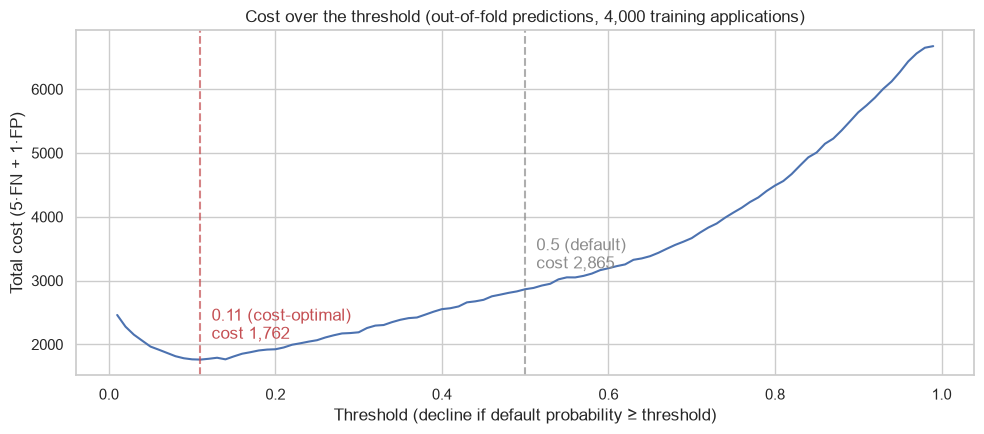

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cost_curve["Threshold"], cost_curve["Cost"], color="#4C72B0")
for t, label, color in [(0.5, "0.5 (default)", "#8C8C8C"),
                        (T_OPT, f"{T_OPT} (cost-optimal)", "#C44E52")]:
    c = cost_curve.loc[cost_curve["Threshold"] == t, "Cost"].iloc[0]
    ax.axvline(t, ls="--", color=color, alpha=0.7)
    ax.annotate(f"{label}\ncost {c:,.0f}", (t, c), xytext=(8, 15),
                textcoords="offset points", color=color)
ax.set_xlabel("Threshold (decline if default probability ≥ threshold)")
ax.set_ylabel("Total cost (5·FN + 1·FP)")
ax.set_title("Cost over the threshold (out-of-fold predictions, 4,000 training applications)")
plt.tight_layout()
plt.show()

In [7]:
# Why is the optimum below the theoretical 1/6? Check calibration by probability band
bands = pd.cut(p_oof, [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0])
pd.DataFrame({"p": p_oof, "y": y_oof}).groupby(bands, observed=True).agg(
    Applications=("y", "size"), Mean_predicted_PD=("p", "mean"),
    Observed_default_rate=("y", "mean")).round(3)

,Applications,Mean_predicted_PD,Observed_default_rate
"(0.0, 0.05]",770,0.022,0.016
"(0.05, 0.1]",446,0.074,0.092
"(0.1, 0.2]",598,0.148,0.211
"(0.2, 0.3]",436,0.248,0.268
"(0.3, 0.4]",339,0.350,0.345
"(0.4, 0.6]",505,0.490,0.378
"(0.6, 0.8]",432,0.703,0.667
"(0.8, 1.0]",474,0.893,0.937


**Result (a).** On the out-of-fold predictions, the cost-optimal threshold is **0.11**. It cuts the total cost from **2,865 to 1,762 (−38%)** compared with the default threshold of 0.5:

| Rule (out-of-fold, 4,000 applications) | Threshold | Cost | Recall | Precision | Approval rate |
|---|---|---|---|---|---|
| Default | 0.50 | 2,865 | 0.616 | 0.733 | 71.9% |
| Theoretical (1/6) | 0.17 | 1,878 | 0.891 | 0.509 | 41.6% |
| **Cost-optimal (CV)** | **0.11** | **1,762** | **0.952** | 0.469 | 32.2% |

- **The price of catching defaults.** Recall rises from 62% to 95%: only 64 of 1,336 defaults slip through instead of 513. In return, many more good customers are declined (1,442 instead of 300), and only about a third of applications are approved automatically. Because so many applications are declined, it matters *how* these decisions are made and explained (part b).
- **Stable choice.** The cost curve is flat around its minimum: every threshold between 0.09 and 0.14 is within 2% of the lowest cost. The per-fold optimum is 0.14 in four folds and 0.09 in one.
- **Why below 1/6?** The calibration table shows that the model *underestimates* risk in the 0.1–0.2 band (predicted 15%, observed 21%). Applications with a predicted PD of 0.11–0.17 are therefore riskier than they look, and declining them pays off. The threshold search picks this up automatically, which is one reason to tune the threshold on data rather than to rely on the formula alone.

### b) The three-zone policy

The cost-optimal threshold decides *whether* an application is approved. The three zones decide *who* makes the decision and *how* it is communicated:

| Zone | Rule | What happens |
|---|---|---|
| 🟢 Green – auto-approve | PD < 0.11 | Approved automatically |
| 🟡 Yellow – manual review | 0.11 ≤ PD < 0.37 | A credit analyst decides, supported by a SHAP explanation. **This is the only manual workload.** |
| 🔴 Red – decline recommended | PD ≥ 0.37 | The system declines and gives the customer a SHAP-based explanation of the main reasons. The customer can request a human review. |

**Why three zones and not just one threshold?**
- **Human oversight.** The EU AI Act classifies credit scoring as a high-risk AI system and requires effective human oversight. Borderline cases, where the model is least certain, are decided by a person.
- **GDPR Art. 22.** Applicants have the right not to be subject to a purely automated decision with significant effects, and the right to obtain human intervention and to contest the decision. Every red-zone decline comes with an explanation and the option to request a human review.
- **Analyst workload.** Reviewing every decline would overload the analysts. Clear cases are handled automatically; the yellow zone concentrates human attention where it matters most.

**The boundaries.**
- **Lower boundary = cost-optimal threshold (0.11).** The zones do not change *which* applications are approved automatically, so the cost and recall from part (a) still apply. All cost figures in this notebook refer to this single-threshold logic.
- **Upper boundary = 0.37 (fixed).** This boundary keeps the manual review workload at about 30% of applications. The table below shows how the workload changes for other choices; in the dashboard the bank can move both boundaries.

In [8]:
T_LOWER = T_OPT   # = cost-optimal threshold
T_UPPER = 0.37    # fixed upper boundary

def zone_of(p, lower=T_LOWER, upper=T_UPPER):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def zone_table(p, y_true, lower=T_LOWER, upper=T_UPPER):
    """Share of applications, defaults and good customers per zone."""
    zone = zone_of(p, lower, upper)
    rows = []
    for z in ["Green", "Yellow", "Red"]:
        m = zone == z
        defaults = int((m & (y_true == 1)).sum())
        rows.append({"Zone": z, "Applications": int(m.sum()), "Share": m.mean(),
                     "Defaults": defaults, "Good customers": int(m.sum()) - defaults,
                     "Default rate": defaults / max(m.sum(), 1),
                     "Share of all defaults": defaults / max((y_true == 1).sum(), 1)})
    table = pd.DataFrame(rows).set_index("Zone")
    table.loc["Total"] = [len(y_true), 1.0, int(y_true.sum()), int((y_true == 0).sum()),
                          y_true.mean(), 1.0]
    return table.astype({"Applications": int, "Defaults": int, "Good customers": int})

print(f"Zones: green < {T_LOWER} ≤ yellow < {T_UPPER} ≤ red  (out-of-fold, training set)")
zone_table(p_oof, y_oof).round(3)

Zones: green < 0.11 ≤ yellow < 0.37 ≤ red  (out-of-fold, training set)


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,1286,0.322,64,1222,0.050,0.048
Yellow,1200,0.300,310,890,0.258,0.232
Red,1514,0.378,962,552,0.635,0.720
Total,4000,1.000,1336,2664,0.334,1.000


,Manual review (yellow),Decline recommended (red),Default rate yellow,Default rate red,Good customers in red
Upper boundary,,,,,
0.20,0.132,0.546,0.218,0.529,1029
0.25,0.191,0.488,0.233,0.561,856
0.30,0.241,0.438,0.241,0.594,710
0.37,0.300,0.378,0.258,0.635,552
0.45,0.363,0.316,0.274,0.692,389
0.50,0.398,0.281,0.282,0.733,300
0.60,0.452,0.226,0.299,0.808,174


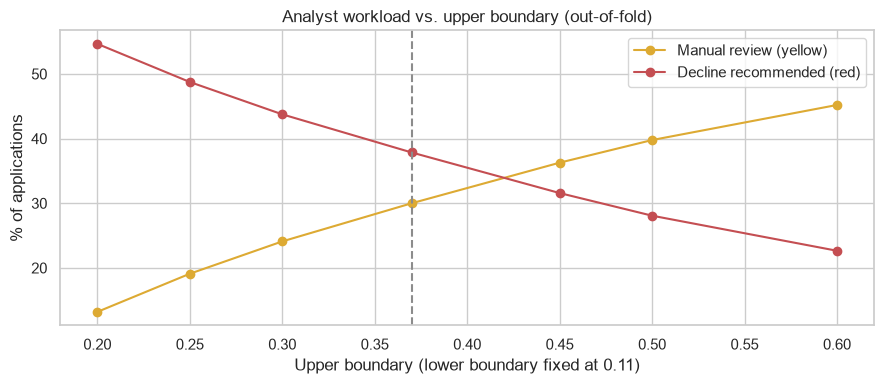

In [9]:
# Analyst workload for different upper boundaries (lower boundary fixed at the cost-optimal threshold)
uppers = [0.20, 0.25, 0.30, 0.37, 0.45, 0.50, 0.60]
workload = []
for u in uppers:
    t = zone_table(p_oof, y_oof, T_LOWER, u)
    workload.append({"Upper boundary": u,
                     "Manual review (yellow)": t.loc["Yellow", "Share"],
                     "Decline recommended (red)": t.loc["Red", "Share"],
                     "Default rate yellow": t.loc["Yellow", "Default rate"],
                     "Default rate red": t.loc["Red", "Default rate"],
                     "Good customers in red": t.loc["Red", "Good customers"]})
workload = pd.DataFrame(workload).set_index("Upper boundary")
display(workload.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(workload.index, 100 * workload["Manual review (yellow)"], marker="o",
        color=ZONE_COLORS["Yellow"], label="Manual review (yellow)")
ax.plot(workload.index, 100 * workload["Decline recommended (red)"], marker="o",
        color=ZONE_COLORS["Red"], label="Decline recommended (red)")
ax.axvline(T_UPPER, ls="--", color="#8C8C8C")
ax.set_xlabel("Upper boundary (lower boundary fixed at 0.11)")
ax.set_ylabel("% of applications")
ax.set_title("Analyst workload vs. upper boundary (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Stability: zone shares in each fold at the fixed boundaries
fold_shares = []
for k in range(5):
    m = fold_id == k
    t = zone_table(p_oof[m], y_oof[m])
    fold_shares.append({"Fold": k + 1, **{z: round(t.loc[z, "Share"], 3) for z in ["Green", "Yellow", "Red"]}})
pd.DataFrame(fold_shares).set_index("Fold").T

Fold,1,2,3,4,5
Green,0.311,0.329,0.308,0.328,0.332
Yellow,0.285,0.315,0.318,0.289,0.294
Red,0.404,0.356,0.375,0.384,0.374


**Result (b).** With the boundaries **0.11 and 0.37**, the out-of-fold applications split as follows:

| Zone (out-of-fold, 4,000 applications) | Share | Defaults | Good customers | Default rate |
|---|---|---|---|---|
| 🟢 Green – auto-approve (PD < 0.11) | 32.2% | 64 | 1,222 | 5.0% |
| 🟡 Yellow – manual review (0.11 – 0.37) | 30.0% | 310 | 890 | 25.8% |
| 🔴 Red – decline recommended (PD ≥ 0.37) | 37.8% | 962 | 552 | 63.5% |

- **Green.** Only 64 of 1,336 defaults (4.8%) are approved automatically, the same as with the single threshold.
- **Yellow.** This zone holds the uncertain cases: about one in four defaults, three in four are good customers. Here an analyst, supported by the SHAP explanation, makes the decision. The manual workload is 30% of applications.
- **Red.** 72% of all defaults fall into this zone, at a default rate of 63.5%. The system declines with a SHAP-based explanation, and the customer can request a human review. These requests are not part of the planned analyst workload.
- **Workload trade-off.** Moving the upper boundary shifts cases between yellow and red: at 0.25 the analysts review 19% of applications, at 0.50 already 40%. A lower boundary means more automated declines of good customers (856 at 0.25 vs. 552 at 0.37); a higher one means more manual work.
- **Stable.** Across the five folds, the yellow share ranges from 28.5% to 31.8%.

### c) Final evaluation on the test set

Now – and only now – we use the test set. We train the logistic regression on all 4,000 training applications and apply the thresholds chosen above **without any change** to the 1,000 test applications.

In [11]:
final_model = make_model().fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()

test_single = pd.DataFrame([single_threshold_metrics(p_test, y_test_arr, t) for t in [0.5, T_OPT]])
test_single.insert(0, "Rule", ["Default (0.5)", f"Cost-optimal ({T_OPT})"])
display(test_single.set_index("Rule").round(3))

for t in [0.5, T_OPT]:
    tn, fp, fn, tp = confusion_matrix(y_test_arr, (p_test >= t).astype(int)).ravel()
    print(f"Threshold {t}: TP {tp}, TN {tn}, FP {fp}, FN {fn}")

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
Default (0.5),0.50,700,70.0,0.626,0.736,0.716,125,75
Cost-optimal (0.11),0.11,409,40.9,0.958,0.486,0.341,14,339


Threshold 0.5: TP 209, TN 591, FP 75, FN 125
Threshold 0.11: TP 320, TN 327, FP 339, FN 14


In [12]:
print(f"Test set – zones {T_LOWER} / {T_UPPER}")
test_zones = zone_table(p_test, y_test_arr)
test_zones.round(3)

Test set – zones 0.11 / 0.37


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,341,0.341,14,327,0.041,0.042
Yellow,273,0.273,75,198,0.275,0.225
Red,386,0.386,245,141,0.635,0.734
Total,1000,1.000,334,666,0.334,1.000


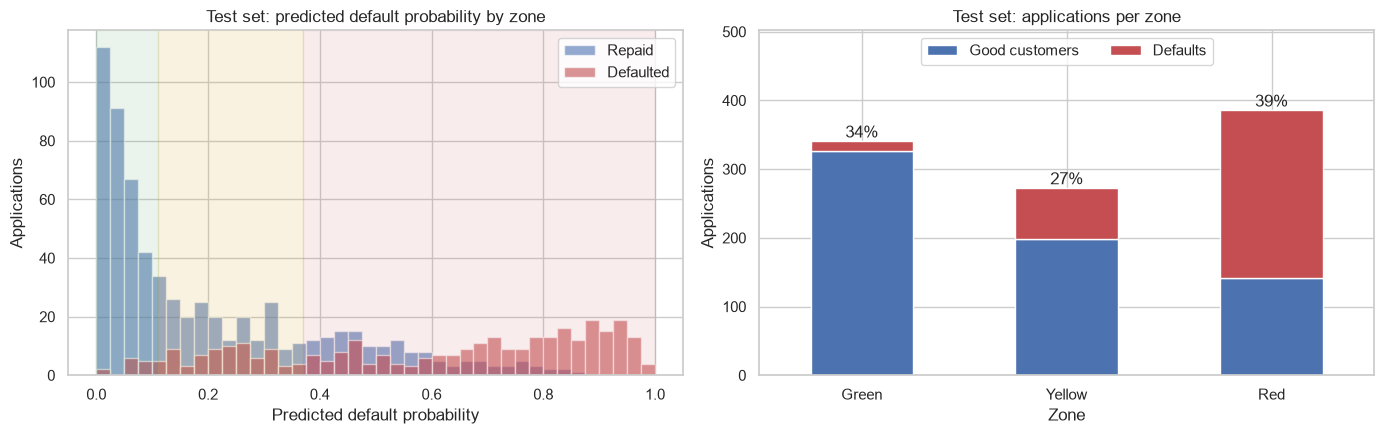

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: distribution of default probabilities with the zone boundaries
bins = np.linspace(0, 1, 41)
axes[0].hist(p_test[y_test_arr == 0], bins=bins, alpha=0.6, label="Repaid", color="#4C72B0")
axes[0].hist(p_test[y_test_arr == 1], bins=bins, alpha=0.6, label="Defaulted", color="#C44E52")
axes[0].axvspan(0, T_LOWER, color=ZONE_COLORS["Green"], alpha=0.12)
axes[0].axvspan(T_LOWER, T_UPPER, color=ZONE_COLORS["Yellow"], alpha=0.15)
axes[0].axvspan(T_UPPER, 1, color=ZONE_COLORS["Red"], alpha=0.10)
axes[0].set_xlabel("Predicted default probability")
axes[0].set_ylabel("Applications")
axes[0].set_title("Test set: predicted default probability by zone")
axes[0].legend()

# Right: composition of each zone
comp = test_zones.loc[["Green", "Yellow", "Red"], ["Good customers", "Defaults"]]
comp.plot.bar(stacked=True, color=["#4C72B0", "#C44E52"], ax=axes[1], rot=0)
axes[1].set_ylim(0, comp.sum(axis=1).max() * 1.3)
axes[1].legend(loc="upper center", ncol=2)
for i, z in enumerate(comp.index):
    axes[1].text(i, comp.loc[z].sum() + 5, f"{test_zones.loc[z, 'Share']:.0%}", ha="center")
axes[1].set_title("Test set: applications per zone")
axes[1].set_ylabel("Applications")
plt.tight_layout()
plt.show()

**Result (c) – final evaluation on the test set.** The thresholds chosen on the training data carry over to the 1,000 unseen test applications.

**Headline result: the cost-based threshold.**

| Rule (test set) | Cost | Recall | Precision | TP | FN | FP | TN |
|---|---|---|---|---|---|---|---|
| Default threshold 0.5 | 700 | 0.626 | 0.736 | 209 | 125 | 75 | 591 |
| **Cost-optimal threshold 0.11** | **409 (−42%)** | **0.958** | 0.486 | 320 | 14 | 339 | 327 |

The cost-based threshold catches **96% instead of 63% of defaults** and lowers the total cost by **42%**. The price is a lower precision: more good customers are declined (339 instead of 75). The test costs per 100 applications (70.0 and 40.9) are close to the out-of-fold values (71.6 and 44.1), so the threshold was not overfitted.

**Zones on the test set.**

| Zone (test set) | Share | Defaults | Good customers | Default rate |
|---|---|---|---|---|
| 🟢 Green – auto-approve | 34.1% | 14 | 327 | 4.1% |
| 🟡 Yellow – manual review | 27.3% | 75 | 198 | 27.5% |
| 🔴 Red – decline recommended | 38.6% | 245 | 141 | 63.5% |

The analyst workload on the test set is 27.3% of applications.

**Decision for CreditParity.** Logistic regression with the cost-optimal threshold **0.11** as the green/yellow boundary and **0.37** as the yellow/red boundary.

**Limitations.**
- The 5:1 cost ratio is an **assumption**. A different ratio leads to a different optimal threshold.
- The cost figures assume that every application with PD ≥ 0.11 is declined. In practice, analysts in the yellow zone and human reviews requested in the red zone may change some of these decisions; the dataset cannot tell us how this affects cost.
- The upper boundary of 0.37 is a workload choice, not an optimum.
- The dataset is synthetic. The strong separation between defaults and good customers may be larger than in real loan data.
- The thresholds have not yet been checked for fairness. Step 6 tests whether some groups land in the yellow or red zone disproportionately often.

**Next step.** Step 6: fairness by Sex, age group and ForeignWorker, for the model and per zone.